In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import chi2_contingency
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.feature_selection import mutual_info_classif


In [2]:
df = pd.read_csv("diabetic_data.csv", na_values=["?"], keep_default_na=False)
print("Dimensions :", df.shape)

/tmp/ipykernel_1081/3165497244.py:1: DtypeWarning: Columns (10) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("diabetic_data.csv", na_values=["?"], keep_default_na=False)


Dimensions : (101766, 50)


In [3]:
df.columns

Index(['encounter_id', 'patient_nbr', 'race', 'gender', 'age', 'weight',
       'admission_type_id', 'discharge_disposition_id', 'admission_source_id',
       'time_in_hospital', 'payer_code', 'medical_specialty',
       'num_lab_procedures', 'num_procedures', 'num_medications',
       'number_outpatient', 'number_emergency', 'number_inpatient', 'diag_1',
       'diag_2', 'diag_3', 'number_diagnoses', 'max_glu_serum', 'A1Cresult',
       'metformin', 'repaglinide', 'nateglinide', 'chlorpropamide',
       'glimepiride', 'acetohexamide', 'glipizide', 'glyburide', 'tolbutamide',
       'pioglitazone', 'rosiglitazone', 'acarbose', 'miglitol', 'troglitazone',
       'tolazamide', 'examide', 'citoglipton', 'insulin',
       'glyburide-metformin', 'glipizide-metformin',
       'glimepiride-pioglitazone', 'metformin-rosiglitazone',
       'metformin-pioglitazone', 'change', 'diabetesMed', 'readmitted'],
      dtype='object')

In [5]:
df.head()

,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),NaN,6,25,1,1,...,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),NaN,1,1,7,3,...,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),NaN,1,1,7,2,...,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),NaN,1,1,7,2,...,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),NaN,1,1,7,1,...,No,Steady,No,No,No,No,No,Ch,Yes,NO


In [6]:
df.describe()

,encounter_id,patient_nbr,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,number_diagnoses
count,1.017660e+05,1.017660e+05,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000
mean,1.652016e+08,5.433040e+07,2.024006,3.715642,5.754437,4.395987,43.095641,1.339730,16.021844,0.369357,0.197836,0.635566,7.422607
std,1.026403e+08,3.869636e+07,1.445403,5.280166,4.064081,2.985108,19.674362,1.705807,8.127566,1.267265,0.930472,1.262863,1.933600
min,1.252200e+04,1.350000e+02,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000
25%,8.496119e+07,2.341322e+07,1.000000,1.000000,1.000000,2.000000,31.000000,0.000000,10.000000,0.000000,0.000000,0.000000,6.000000
50%,1.523890e+08,4.550514e+07,1.000000,1.000000,7.000000,4.000000,44.000000,1.000000,15.000000,0.000000,0.000000,0.000000,8.000000
75%,2.302709e+08,8.754595e+07,3.000000,4.000000,7.000000,6.000000,57.000000,2.000000,20.000000,0.000000,0.000000,1.000000,9.000000
max,4.438672e+08,1.895026e+08,8.000000,28.000000,25.000000,14.000000,132.000000,6.000000,81.000000,42.000000,76.000000,21.000000,16.000000


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 101766 entries, 0 to 101765
Data columns (total 50 columns):
 #   Column                    Non-Null Count   Dtype 
---  ------                    --------------   ----- 
 0   encounter_id              101766 non-null  int64 
 1   patient_nbr               101766 non-null  int64 
 2   race                      99493 non-null   object
 3   gender                    101766 non-null  object
 4   age                       101766 non-null  object
 5   weight                    3197 non-null    object
 6   admission_type_id         101766 non-null  int64 
 7   discharge_disposition_id  101766 non-null  int64 
 8   admission_source_id       101766 non-null  int64 
 9   time_in_hospital          101766 non-null  int64 
 10  payer_code                61510 non-null   object
 11  medical_specialty         51817 non-null   object
 12  num_lab_procedures        101766 non-null  int64 
 13  num_procedures            101766 non-null  int64 
 14  num_

In [8]:
df.describe(include="object")

,race,gender,age,weight,payer_code,medical_specialty,diag_1,diag_2,diag_3,max_glu_serum,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
count,99493,101766,101766,3197,61510,51817,101745,101408,100343,101766,...,101766,101766,101766,101766,101766,101766,101766,101766,101766,101766
unique,5,3,10,9,17,72,716,748,789,4,...,1,4,4,2,2,2,2,2,2,3
top,Caucasian,Female,[70-80),[75-100),MC,InternalMedicine,428,276,250,None,...,No,No,No,No,No,No,No,No,Yes,NO
freq,76099,54708,26068,1336,32439,14635,6862,6752,11555,96420,...,101766,47383,101060,101753,101765,101764,101765,54755,78363,54864


change
No    54755
Ch    47011
Name: count, dtype: int64

Répartition de la cible (%) :
target
0    53.8
1    46.2
Name: proportion, dtype: float64


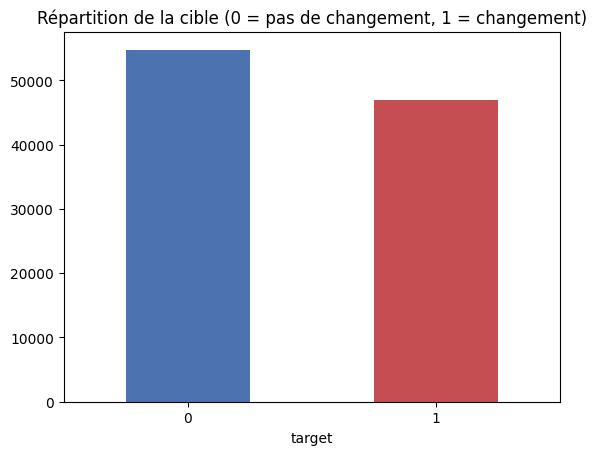

In [9]:
print(df["change"].value_counts())
df["target"] = (df["change"] == "Ch").astype(int)
print("\nRépartition de la cible (%) :")
print(df["target"].value_counts(normalize=True).mul(100).round(2))

df["target"].value_counts().plot(kind="bar", color=["#4C72B0", "#C44E52"])
plt.title("Répartition de la cible (0 = pas de changement, 1 = changement)")
plt.xticks(rotation=0)
plt.show()

In [10]:
print("Lignes entièrement dupliquées :", df.duplicated().sum())
print("encounter_id dupliqués        :", df["encounter_id"].duplicated().sum())
print("Patients uniques / lignes     :", df["patient_nbr"].nunique(), "/", len(df))

Lignes entièrement dupliquées : 0
encounter_id dupliqués        : 0
Patients uniques / lignes     : 71518 / 101766


In [11]:
df.drop_duplicates(inplace=True)
df = df.sort_values("encounter_id").drop_duplicates(subset="patient_nbr", keep="first")

In [12]:
print("Lignes dupliquées  :", df.duplicated().sum())
print("Patients dupliqués :", df["patient_nbr"].duplicated().sum())
print("Nouvelles dimensions :", df.shape)

# Les identifiants n'ont aucune valeur prédictive
df.drop(columns=["encounter_id", "patient_nbr"], inplace=True)

Lignes dupliquées  : 0
Patients dupliqués : 0
Nouvelles dimensions : (71518, 51)


Pourcentage de valeurs manquantes :
weight               96.01
medical_specialty    48.21
payer_code           43.41
race                  2.72
diag_3                1.71
diag_2                0.41
diag_1                0.02
dtype: float64


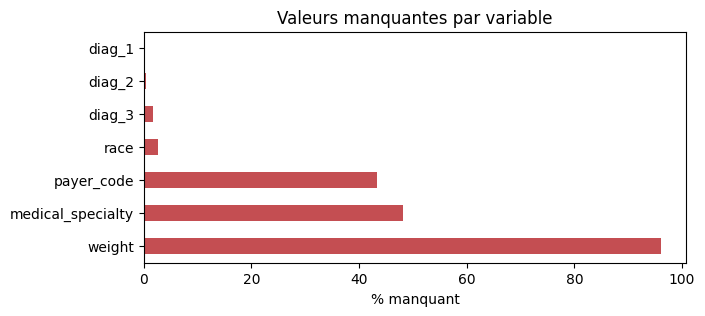

In [13]:
missing = df.isnull().mean().mul(100).round(2).sort_values(ascending=False)
print("Pourcentage de valeurs manquantes :")
print(missing[missing > 0])

missing[missing > 0].plot(kind="barh", figsize=(7, 3), color="#C44E52")
plt.xlabel("% manquant")
plt.title("Valeurs manquantes par variable")
plt.show()

In [14]:
df.drop(columns=["weight", "payer_code"], inplace=True)

for col in ["medical_specialty", "race", "diag_1", "diag_2", "diag_3"]:
    df[col] = df[col].fillna("Unknown")

df = df[df["gender"] != "Unknown/Invalid"]

exclus = [11, 13, 14, 19, 20, 21]
df = df[~df["discharge_disposition_id"].isin(exclus)]

print("Valeurs manquantes restantes :", df.isnull().sum().sum())
print("Dimensions :", df.shape)

Valeurs manquantes restantes : 0
Dimensions : (69970, 47)


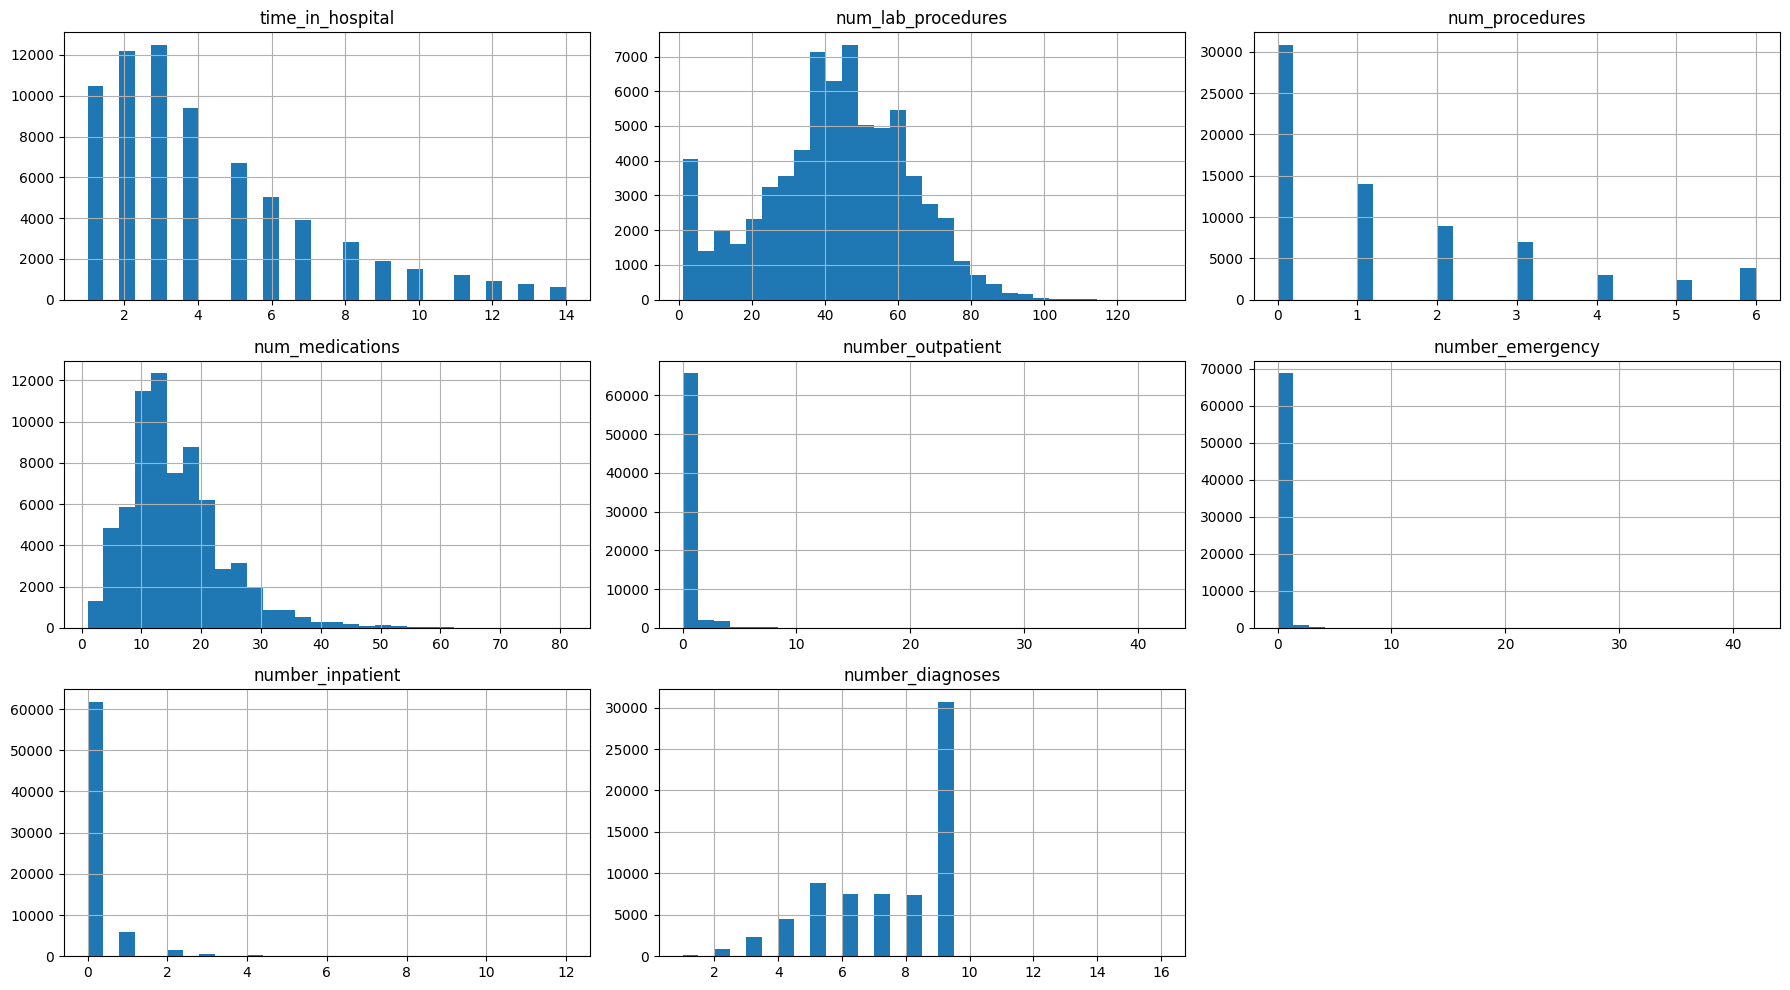

In [15]:
num_cols_viz = ["time_in_hospital", "num_lab_procedures", "num_procedures", "num_medications",
                "number_outpatient", "number_emergency", "number_inpatient", "number_diagnoses"]
df[num_cols_viz].hist(figsize=(18, 10), bins=30)
plt.tight_layout()
plt.show()

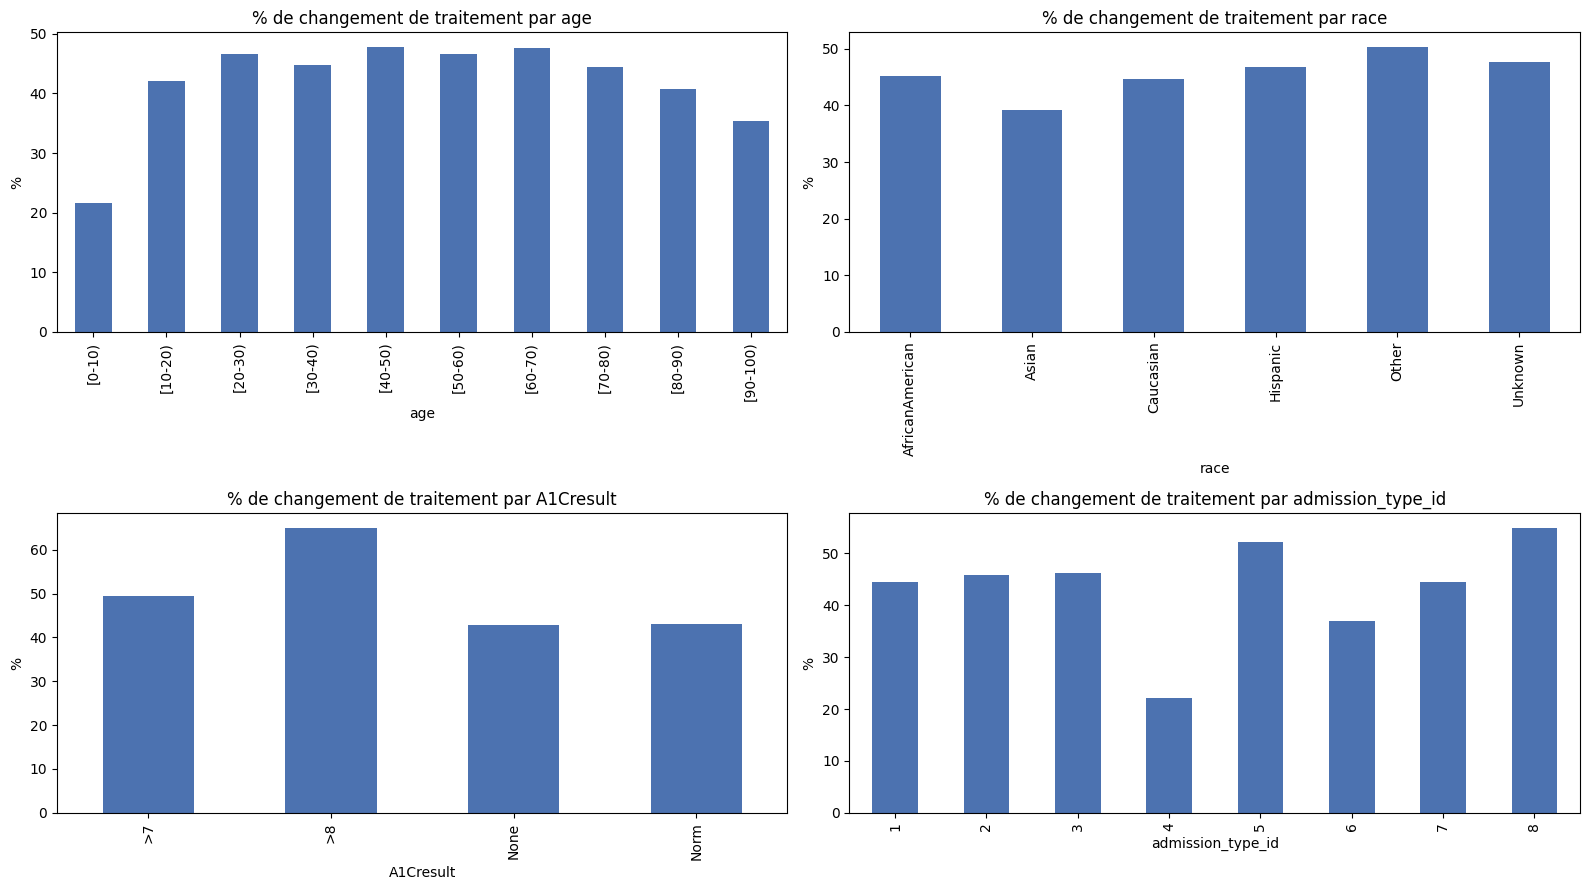

In [16]:
import matplotlib.pyplot as plt

# Taux de changement de traitement selon quelques variables catégorielles (ou numériques transformées)
fig, axes = plt.subplots(2, 2, figsize=(16, 9))

# Remplacer "age" par "age_num" ici :
for ax, col in zip(axes.ravel(), ["age", "race", "A1Cresult", "admission_type_id"]):
    rate = df.groupby(col)["target"].mean().mul(100)
    rate.plot(kind="bar", ax=ax, color="#4C72B0")
    ax.set_title(f"% de changement de traitement par {col}")
    ax.set_ylabel("%")

plt.tight_layout()
plt.show()

In [17]:
ADMISSION_ONLY = False   # True = uniquement ce qui est connu à l'admission



meds = ["metformin", "repaglinide", "nateglinide", "chlorpropamide", "glimepiride", "acetohexamide",

        "glipizide", "glyburide", "tolbutamide", "pioglitazone", "rosiglitazone", "acarbose", "miglitol",

        "troglitazone", "tolazamide", "examide", "citoglipton", "insulin", "glyburide-metformin",

        "glipizide-metformin", "glimepiride-pioglitazone", "metformin-rosiglitazone", "metformin-pioglitazone"]



leakage_cols = meds + ["change", "diabetesMed", "readmitted"]

in_stay_cols = ["time_in_hospital", "num_lab_procedures", "num_procedures", "num_medications",

                "number_diagnoses", "discharge_disposition_id"]



df.drop(columns=[c for c in leakage_cols if c in df.columns], inplace=True)

if ADMISSION_ONLY:

    df.drop(columns=in_stay_cols, inplace=True)



print("Variables restantes :", df.shape[1] - 1)

Variables restantes : 20


In [18]:
# Age : milieu de la tranche

# Age : milieu de la tranche (exécuté uniquement si 'age' existe encore)

if "age" in df.columns:

    df["age_num"] = df["age"].str.extract(r"\[(\d+)-(\d+)\)").astype(int).mean(axis=1)

    df.drop(columns="age", inplace=True)

else:

    print("La colonne 'age' a déjà été traitée ou supprimée.")



# Diagnostics : regroupement CIM-9

def group_diag(code):

    if code == "Unknown":

        return "Unknown"

    if str(code).startswith(("V", "E")):

        return "Other"

    c = float(code); i = int(c)

    if 390 <= c < 460 or i == 785: return "Circulatory"

    if 460 <= c < 520 or i == 786: return "Respiratory"

    if 520 <= c < 580 or i == 787: return "Digestive"

    if i == 250:                   return "Diabetes"

    if 800 <= c < 1000:            return "Injury"

    if 710 <= c < 740:             return "Musculoskeletal"

    if 580 <= c < 630 or i == 788: return "Genitourinary"

    if 140 <= c < 240:             return "Neoplasms"

    return "Other"



for col in ["diag_1", "diag_2", "diag_3"]:

    df[col] = df[col].apply(group_diag)



# Identifiants -> catégories (d'après IDS_mapping.csv)

df["admission_type_id"] = df["admission_type_id"].map(

    {1: "Emergency", 2: "Urgent", 3: "Elective", 7: "Trauma"}).fillna("Unknown")



def group_source(x):

    if x in (1, 2, 3):                       return "Referral"

    if x == 7:                               return "Emergency_Room"

    if x in (4, 5, 6, 10, 18, 22, 25, 26):   return "Transfer"

    return "Other_Unknown"

df["admission_source_id"] = df["admission_source_id"].apply(group_source)



if "discharge_disposition_id" in df.columns:

    def group_disch(x):

        if x == 1:                                      return "Home"

        if x in (6, 8):                                 return "Home_health"

        if x in (2, 3, 4, 5, 22, 23, 24, 27, 28, 29, 30): return "Facility"

        return "Other"

    df["discharge_disposition_id"] = df["discharge_disposition_id"].apply(group_disch)



df.rename(columns={"admission_type_id": "admission_type",

                   "admission_source_id": "admission_source",

                   "discharge_disposition_id": "discharge_disposition"}, inplace=True)



# Variables asymétriques

for col in ["number_outpatient", "number_emergency", "number_inpatient"]:

    df[col] = np.log1p(df[col])



print(df.dtypes)

df.head()

race                      object
gender                    object
admission_type            object
discharge_disposition     object
admission_source          object
time_in_hospital           int64
medical_specialty         object
num_lab_procedures         int64
num_procedures             int64
num_medications            int64
number_outpatient        float64
number_emergency         float64
number_inpatient         float64
diag_1                    object
diag_2                    object
diag_3                    object
number_diagnoses           int64
max_glu_serum             object
A1Cresult                 object
target                     int64
age_num                  float64
dtype: object


,race,gender,admission_type,discharge_disposition,admission_source,time_in_hospital,medical_specialty,num_lab_procedures,num_procedures,num_medications,...,number_emergency,number_inpatient,diag_1,diag_2,diag_3,number_diagnoses,max_glu_serum,A1Cresult,target,age_num
8,Caucasian,Female,Urgent,Home,Transfer,13,Unknown,68,2,28,...,0.0,0.0,Circulatory,Circulatory,Other,8,None,None,1,85.0
9,Caucasian,Female,Elective,Facility,Transfer,12,InternalMedicine,33,3,18,...,0.0,0.0,Circulatory,Neoplasms,Respiratory,8,None,None,1,95.0
4,Caucasian,Male,Emergency,Home,Emergency_Room,1,Unknown,51,0,8,...,0.0,0.0,Neoplasms,Neoplasms,Diabetes,5,None,None,1,45.0
10,AfricanAmerican,Female,Emergency,Home,Emergency_Room,9,Unknown,47,2,17,...,0.0,0.0,Diabetes,Circulatory,Injury,9,None,None,0,45.0
5,Caucasian,Male,Urgent,Home,Referral,3,Unknown,31,6,16,...,0.0,0.0,Circulatory,Circulatory,Diabetes,9,None,None,0,55.0


In [19]:
num_cols = df.drop(columns="target").select_dtypes(include="number").columns.tolist()

cat_cols = df.drop(columns="target").select_dtypes(include="object").columns.tolist()



# Écrêtage aux percentiles 1% et 99%

bounds = df[num_cols].quantile([0.01, 0.99])

df[num_cols] = df[num_cols].clip(bounds.loc[0.01], bounds.loc[0.99], axis=1)



# medical_specialty : 10 spécialités les plus fréquentes + 'Other'

top_spec = df["medical_specialty"].value_counts().nlargest(10).index

df["medical_specialty"] = df["medical_specialty"].where(df["medical_specialty"].isin(top_spec), "Other")



print("Numériques   :", num_cols)

print("Catégorielles:", cat_cols)



X = df.drop(columns="target")

y = df["target"]



preprocessor = ColumnTransformer([

    ("num", StandardScaler(), num_cols),

    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols),

])

preprocessor.set_output(transform="pandas")



X_prepared = preprocessor.fit_transform(X)

df_prepared = X_prepared.assign(target=y.values)



print("Dimensions finales :", df_prepared.shape)

df_prepared.head()

Numériques   : ['time_in_hospital', 'num_lab_procedures', 'num_procedures', 'num_medications', 'number_outpatient', 'number_emergency', 'number_inpatient', 'number_diagnoses', 'age_num']
Catégorielles: ['race', 'gender', 'admission_type', 'discharge_disposition', 'admission_source', 'medical_specialty', 'diag_1', 'diag_2', 'diag_3', 'max_glu_serum', 'A1Cresult']
Dimensions finales : (69970, 80)


,num__time_in_hospital,num__num_lab_procedures,num__num_procedures,num__num_medications,num__number_outpatient,num__number_emergency,num__number_inpatient,num__number_diagnoses,num__age_num,cat__race_AfricanAmerican,...,cat__diag_3_Unknown,cat__max_glu_serum_>200,cat__max_glu_serum_>300,cat__max_glu_serum_None,cat__max_glu_serum_Norm,cat__A1Cresult_>7,cat__A1Cresult_>8,cat__A1Cresult_None,cat__A1Cresult_Norm,target
8,3.007338,1.275306,0.326969,1.565434,-0.362365,-0.273418,-0.347843,0.392934,1.244998,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1
9,2.663088,-0.497064,0.896088,0.303293,-0.362365,-0.273418,-0.347843,0.392934,1.885433,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1
4,-1.123661,0.414440,-0.811269,-0.958849,-0.362365,-0.273418,-0.347843,-1.121197,-1.316739,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1
10,1.630338,0.211884,0.326969,0.177079,-0.362365,-0.273418,-0.347843,0.897645,-1.316739,1.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0
5,-0.435161,-0.598342,2.603444,0.050864,-0.362365,-0.273418,-0.347843,0.897645,-0.676305,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0


--- Corrélation de chaque variable avec la cible (target) ---
target                              1.000000
num__num_medications                0.247448
cat__A1Cresult_>8                   0.126027
num__time_in_hospital               0.112040
cat__diag_1_Diabetes                0.080995
                                      ...   
cat__diag_2_Digestive              -0.039272
cat__max_glu_serum_Norm            -0.047403
cat__discharge_disposition_Other   -0.051820
cat__diag_1_Digestive              -0.081557
cat__A1Cresult_None                -0.096487
Name: target, Length: 80, dtype: float64


/tmp/ipykernel_1081/3607687844.py:33: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=target_correlation.values, y=target_correlation.index, palette="vlag")


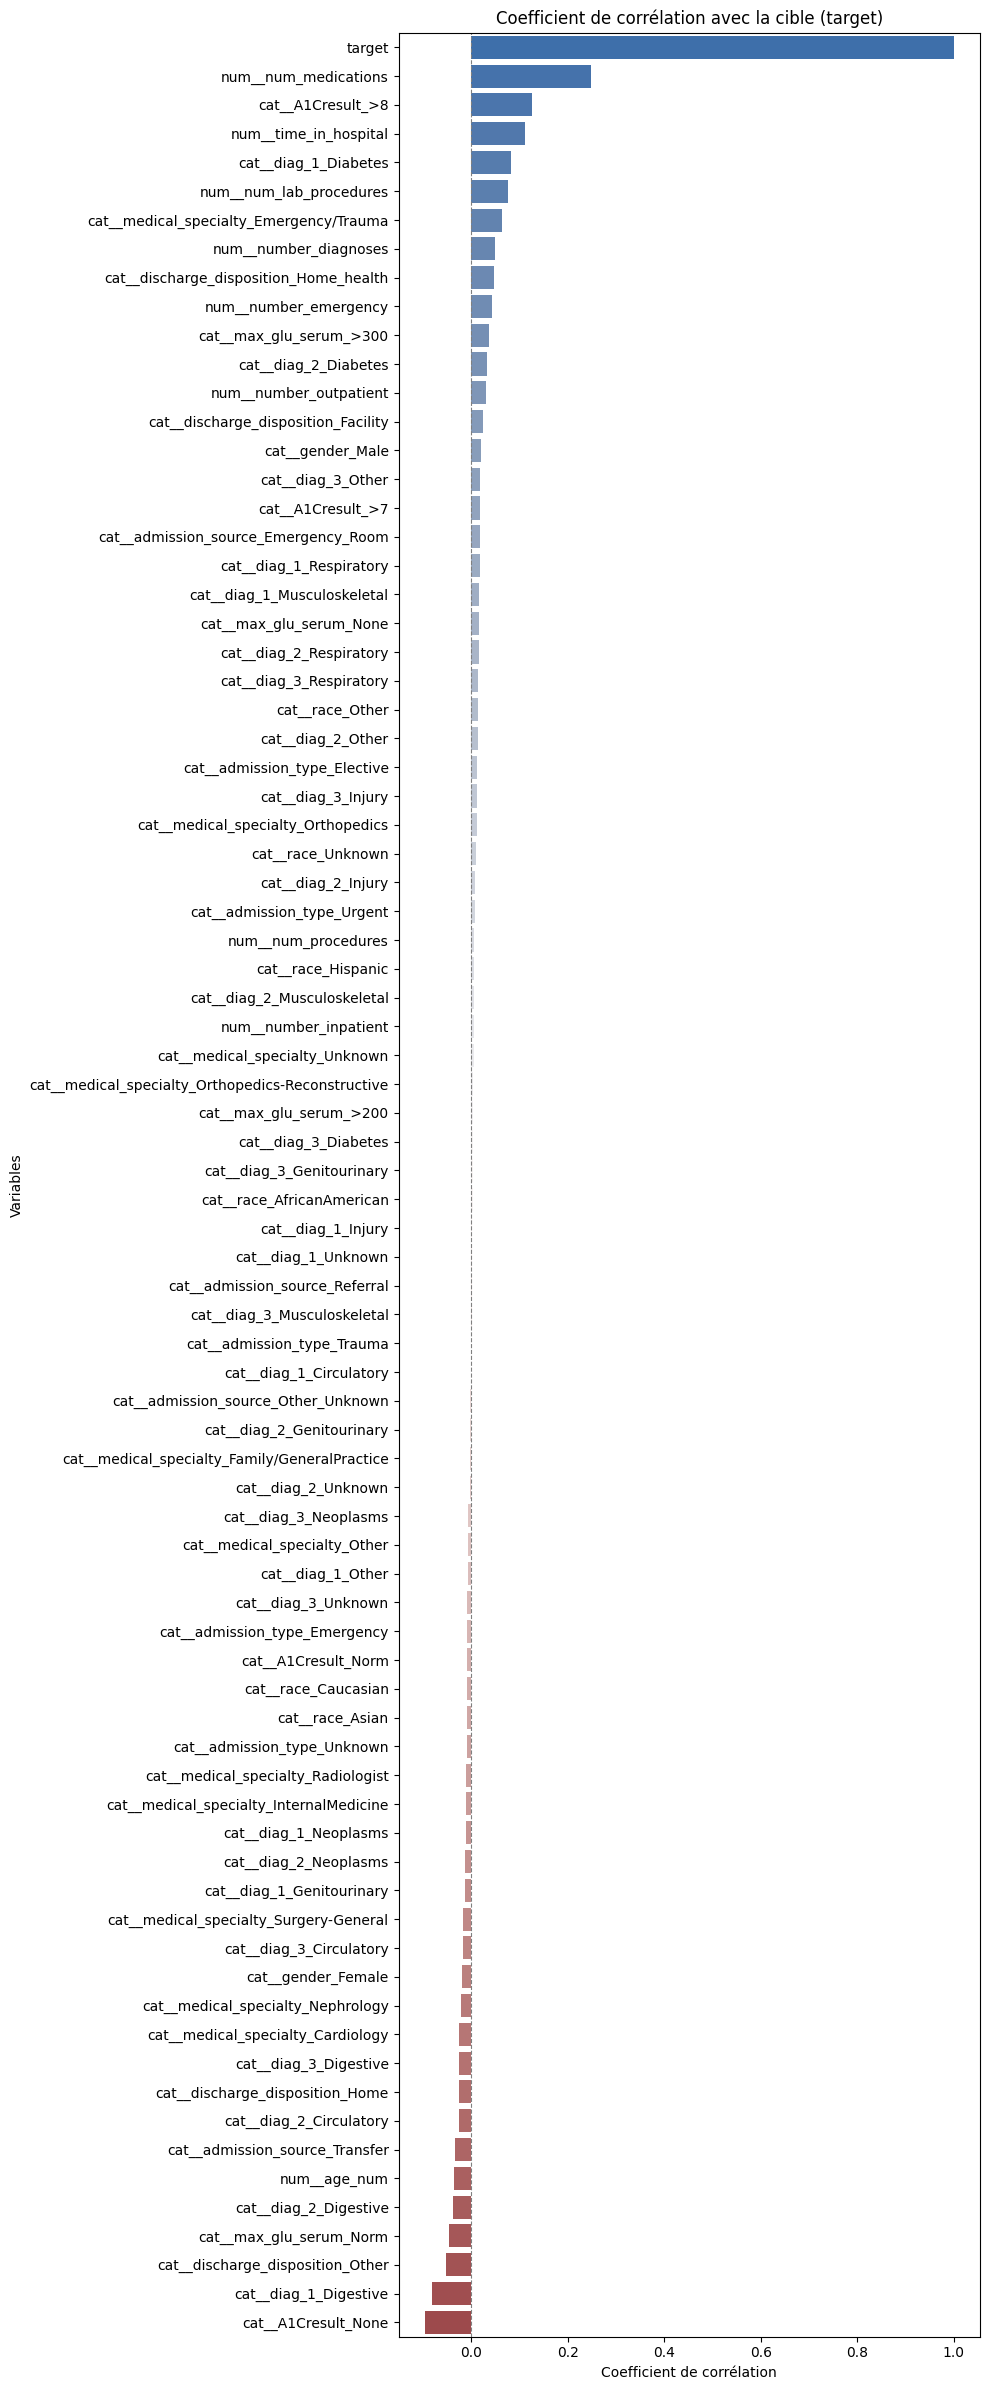

In [20]:
# Calcul de la matrice de corrélation globale

corr_matrix = df_prepared.corr()



# Extraction des corrélations uniquement par rapport à la colonne 'target'

if "target" in corr_matrix.columns:

    target_correlation = corr_matrix["target"].sort_values(ascending=False)



    # Affichage sous forme de tableau trié

    print("--- Corrélation de chaque variable avec la cible (target) ---")

    print(target_correlation)



    # Visualisation graphique sous forme de diagramme à barres (très pratique pour voir les liens positifs et négatifs)

    import matplotlib.pyplot as plt

    import seaborn as sns



    plt.figure(figsize=(10, len(target_correlation) * 0.3)) # Ajuste la hauteur dynamiquement selon le nombre de variables

    sns.barplot(x=target_correlation.values, y=target_correlation.index, palette="vlag")

    plt.title("Coefficient de corrélation avec la cible (target)")

    plt.xlabel("Coefficient de corrélation")

    plt.ylabel("Variables")

    plt.axvline(0, color='grey', linestyle='--', linewidth=0.8)

    plt.tight_layout()

    plt.show()

In [21]:
import time

from sklearn.model_selection import RandomizedSearchCV, GridSearchCV

from sklearn.metrics import accuracy_score, f1_score, roc_auc_score

from sklearn.linear_model import LogisticRegression

from sklearn.ensemble import RandomForestClassifier

from xgboost import XGBClassifier



# 1. Préparation des données (X et y)

X = df_prepared.drop(columns=['target'])

y = df_prepared['target']



X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)



# 2. Dictionnaire des grilles d'hyperparamètres pour chaque modèle

optimization_configs = {

    "Régression Logistique": {

        "model": LogisticRegression(max_iter=1000, random_state=42),

        "params": {

            'C': [0.001, 0.01, 0.1, 1.0, 10, 100],

            'solver': ['liblinear', 'lbfgs']

        },

        "search_type": "grid"

    },

    "Random Forest": {

        "model": RandomForestClassifier(random_state=42, n_jobs=-1),

        "params": {

            'n_estimators': [100, 200, 300],

            'max_depth': [10, 15, 20, None],

            'min_samples_split': [2, 5, 10],

            'min_samples_leaf': [1, 2, 4]

        },

        "search_type": "random",

        "n_iter": 10

    },

    "XGBoost": {

        "model": XGBClassifier(random_state=42, n_jobs=-1),

        "params": {

            'n_estimators': [100, 200, 300],

            'learning_rate': [0.01, 0.05, 0.1],

            'max_depth': [3, 5, 7],

            'subsample': [0.8, 1.0],

            'colsample_bytree': [0.8, 1.0]

        },

        "search_type": "random",

        "n_iter": 10

    }

}



best_models = {}

results_optimized = {}



# 3. Boucle d'optimisation et d'évaluation

for name, config in optimization_configs.items():

    print(f"\n--- Optimisation en cours : {name} ---")

    start_time = time.time()



    if config["search_type"] == "grid":

        search = GridSearchCV(

            estimator=config["model"],

            param_grid=config["params"],

            scoring='roc_auc',

            cv=3,

            n_jobs=-1

        )

    else:

        search = RandomizedSearchCV(

            estimator=config["model"],

            param_distributions=config["params"],

            n_iter=config["iter"] if "iter" in config else config.get("n_iter", 10),

            scoring='roc_auc',

            cv=3,

            random_state=42,

            n_jobs=-1

        )



    search.fit(X_train, y_train)

    train_time = time.time() - start_time



    best_model = search.best_estimator_

    best_models[name] = best_model



    # Prédictions sur le test

    y_pred = best_model.predict(X_test)

    y_proba = best_model.predict_proba(X_test)[:, 1]



    acc = accuracy_score(y_test, y_pred)

    f1 = f1_score(y_test, y_pred, average='weighted')

    auc = roc_auc_score(y_test, y_proba)



    results_optimized[name] = {

        "Meilleurs Paramètres": search.best_params_,

        "Temps (s)": train_time,

        "Accuracy": acc,

        "F1-Score": f1,

        "AUC-ROC": auc

    }



    print(f"Terminé en {train_time:.2f}s | Meilleurs paramètres : {search.best_params_}")

    print(f"-> Accuracy : {acc:.4f} | F1-Score : {f1:.4f} | AUC-ROC : {auc:.4f}")



# 4. Résumé global

print("\n================================")

print("RÉSUMÉ DES PERFORMANCES OPTIMISÉES")

print("================================")

for name, metrics in results_optimized.items():

    print(f"\n{name} :")

    for k, v in metrics.items():

        if k != "Meilleurs Paramètres":

            print(f"  - {k}: {v:.4f}" if isinstance(v, float) else f"  - {k}: {v}")

        else:

            print(f"  - {k}: {v}")


--- Optimisation en cours : Régression Logistique ---
Terminé en 23.31s | Meilleurs paramètres : {'C': 0.01, 'solver': 'lbfgs'}
-> Accuracy : 0.6343 | F1-Score : 0.6270 | AUC-ROC : 0.6918

--- Optimisation en cours : Random Forest ---


/usr/local/lib/python3.13/dist-packages/joblib/externals/loky/process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


Terminé en 388.28s | Meilleurs paramètres : {'n_estimators': 300, 'min_samples_split': 5, 'min_samples_leaf': 4, 'max_depth': 20}
-> Accuracy : 0.6449 | F1-Score : 0.6391 | AUC-ROC : 0.7075

--- Optimisation en cours : XGBoost ---
Terminé en 62.63s | Meilleurs paramètres : {'subsample': 1.0, 'n_estimators': 200, 'max_depth': 5, 'learning_rate': 0.1, 'colsample_bytree': 0.8}
-> Accuracy : 0.6537 | F1-Score : 0.6510 | AUC-ROC : 0.7153

RÉSUMÉ DES PERFORMANCES OPTIMISÉES

Régression Logistique :
  - Meilleurs Paramètres: {'C': 0.01, 'solver': 'lbfgs'}
  - Temps (s): 23.3086
  - Accuracy: 0.6343
  - F1-Score: 0.6270
  - AUC-ROC: 0.6918

Random Forest :
  - Meilleurs Paramètres: {'n_estimators': 300, 'min_samples_split': 5, 'min_samples_leaf': 4, 'max_depth': 20}
  - Temps (s): 388.2776
  - Accuracy: 0.6449
  - F1-Score: 0.6391
  - AUC-ROC: 0.7075

XGBoost :
  - Meilleurs Paramètres: {'subsample': 1.0, 'n_estimators': 200, 'max_depth': 5, 'learning_rate': 0.1, 'colsample_bytree': 0.8}
  - T